In [7]:
import glob, json, os, re
import numpy as np
import pandas as pd
from IPython.display import display, HTML

found = glob.glob("/kaggle/input/**/C1_Naive.json", recursive=True)
if not found:
    raise FileNotFoundError("C1_Naive.json bulunamadı.")

base_dir = os.path.dirname(found[0])
words = lambda s: re.sub(r'[^\w\s]', '', str(s).lower()).split()

def show_condition_table(cond_name, max_rows=None):
    path = os.path.join(base_dir, f"{cond_name}.json")
    with open(path, "r", encoding="utf-8") as f:
        rows = json.load(f)

    df = pd.DataFrame(rows)
    ans_df = df[df["Recall@3"].notna()]
    g_avg = np.mean([len(words(x)) for x in ans_df["gold"]])
    o_avg = np.mean([len(words(x)) for x in ans_df["output"]])

    cols = [c for c in ["sample_id", "question", "gold", "output", "Recall@3", "MRR", "EM", "F1", "Faithfulness", "Abstention"] if c in df.columns]
    view = df[cols].copy()
    if max_rows:
        view = view.head(max_rows)

    for col in ["Recall@3", "MRR", "EM", "F1", "Faithfulness", "Abstention"]:
        if col in view.columns:
            view[col] = view[col].apply(lambda x: "-" if pd.isna(x) else f"{x:.2f}")

    header_html = f"""
    <div style="font-family:sans-serif; background:#f4f6f9; border-left:4px solid #4C78A8; padding:8px 12px; margin-bottom:8px;">
        <b>{cond_name}</b> &nbsp;|&nbsp; Total: <b>{len(df)}</b> &nbsp;|&nbsp;
        Gold avg (n=100): <b>{g_avg:.2f} words</b> &nbsp;|&nbsp;
        Model avg (n=100): <b>{o_avg:.2f} words</b>
    </div>
    """
    display(HTML(header_html))

    styled = (
        view.style
        .set_properties(**{"text-align": "left", "font-size": "12px", "padding": "6px", "border": "1px solid #ddd"})
        .set_table_styles([{"selector": "th", "props": [("background-color", "#2c3e50"), ("color", "white"), ("text-align", "left"), ("padding", "6px")]}])
        .hide(axis="index")
    )
    display(HTML(f'<div style="max-height:480px; overflow-y:auto; border:1px solid #ccc;">{styled.to_html()}</div>'))
    return rows

c1_rows = show_condition_table("C1_Naive")

sample_id,question,gold,output,Recall@3,MRR,EM,F1,Faithfulness,Abstention
56df5a4d8bc80c19004e4af0,What place was Oklahoma cities population ranked in the nation in 2012?,42nd,UNANSWERABLE,0.00,0.00,0.00,0.00,-,-
56be9d3d3aeaaa14008c9172,One of Beyonce's most successful tours yet was which one?,The Mrs. Carter Show,The Beyoncé Experience,0.00,0.00,0.00,0.29,1.00,-
56d1162317492d1400aab8ef,This storyline takes place alternate from what storyline?,The Wind Waker,The Twilight Princess storyline.,0.00,0.00,0.00,0.29,0.75,-
56cf1ba9aab44d1400b88d90,In what borough is the Ditmas Park neighborhood located?,Brooklyn,Bronx,1.00,1.00,0.00,0.00,1.00,-
56deebdc3277331400b4d821,What medical group is present at all Brigades but not part of it?,a field ambulance,Field Ambulance,1.00,0.50,0.00,0.80,1.00,-
56d0817d234ae51400d9c335,What materials absorb sunlight and create higher temperatures than natural materials?,asphalt and concrete,Deciduous trees and plants absorb sunlight and create higher temperatures than natural materials through photosynthesis.,0.00,0.00,0.00,0.11,0.60,-
56d97d10dc89441400fdb4e0,What did Xinhua call protesters?,radicals,"Xinhua called protesters ""radicals"".",1.00,1.00,0.00,0.40,1.00,-
56de8a8c4396321400ee29ff,When did Schwarzenegger purchase the rights to the film Pumping Iron?,1991,1991,1.00,1.00,1.00,1.00,1.00,-
56df930f38dc421700152072,Bell used his own design in all public demonstrations and what?,commercial use,Bell used his own design in all public demonstrations and lectures.,0.00,0.00,0.00,0.00,0.64,-
56d4831f2ccc5a1400d83154,Independent Women Part I was on which 2000 film's soundtrack?,Charlie's Angels.,Charlie's Angels,1.00,1.00,1.00,1.00,1.00,-


In [9]:
c2_rows = show_condition_table("C2_Hybrid")

sample_id,question,gold,output,Recall@3,MRR,EM,F1,Faithfulness,Abstention
56df5a4d8bc80c19004e4af0,What place was Oklahoma cities population ranked in the nation in 2012?,42nd,The Oklahoma City metropolitan area was the 42nd largest in the nation as of 2012.,1.00,0.33,0.00,0.12,1.00,-
56be9d3d3aeaaa14008c9172,One of Beyonce's most successful tours yet was which one?,The Mrs. Carter Show,The most successful tour of Beyoncé's career and one of the most successful tours of all time was the World Tour.,0.00,0.00,0.00,0.08,1.00,-
56d1162317492d1400aab8ef,This storyline takes place alternate from what storyline?,The Wind Waker,Ocarina of Time and Majora's Mask,1.00,1.00,0.00,0.00,1.00,-
56cf1ba9aab44d1400b88d90,In what borough is the Ditmas Park neighborhood located?,Brooklyn,Bronx,1.00,1.00,0.00,0.00,1.00,-
56deebdc3277331400b4d821,What medical group is present at all Brigades but not part of it?,a field ambulance,Field Ambulance,1.00,1.00,0.00,0.80,1.00,-
56d0817d234ae51400d9c335,What materials absorb sunlight and create higher temperatures than natural materials?,asphalt and concrete,Asphalt and concrete absorb more sunlight and generate higher temperatures compared to natural materials like soil and rock due to their lower albedo and higher heat capacity.,1.00,0.50,0.00,0.20,0.59,-
56d97d10dc89441400fdb4e0,What did Xinhua call protesters?,radicals,"Xinhua called protesters ""radicals"".",1.00,1.00,0.00,0.40,1.00,-
56de8a8c4396321400ee29ff,When did Schwarzenegger purchase the rights to the film Pumping Iron?,1991,"In 1991, Schwarzenegger purchased the rights to the film Pumping Iron, its outtakes, and associated still photography.",1.00,1.00,0.00,0.11,1.00,-
56df930f38dc421700152072,Bell used his own design in all public demonstrations and what?,commercial use,Bell used his own design in all public demonstrations except for the liquid transmitter.,1.00,0.33,0.00,0.00,0.79,-
56d4831f2ccc5a1400d83154,Independent Women Part I was on which 2000 film's soundtrack?,Charlie's Angels.,"Independent Women Part I was on the soundtrack to the 2000 film, Charlie's Angels.",1.00,1.00,0.00,0.25,1.00,-


In [10]:
c3_rows = show_condition_table("C3_Recursive")

sample_id,question,gold,output,Recall@3,MRR,EM,F1,Faithfulness,Abstention
56df5a4d8bc80c19004e4af0,What place was Oklahoma cities population ranked in the nation in 2012?,42nd,The Oklahoma City metropolitan statistical area was ranked 42nd largest in the nation based on population as of 2012.,1.00,1.00,0.00,0.10,0.95,-
56be9d3d3aeaaa14008c9172,One of Beyonce's most successful tours yet was which one?,The Mrs. Carter Show,The 2011 4 Intimate Nights with Beyoncé concerts were considered one of her most successful tours.,0.00,0.00,0.00,0.10,0.69,-
56d1162317492d1400aab8ef,This storyline takes place alternate from what storyline?,The Wind Waker,A Link to the Past,1.00,1.00,0.00,0.25,1.00,-
56cf1ba9aab44d1400b88d90,In what borough is the Ditmas Park neighborhood located?,Brooklyn,Brooklyn,1.00,1.00,1.00,1.00,1.00,-
56deebdc3277331400b4d821,What medical group is present at all Brigades but not part of it?,a field ambulance,Field ambulance.,1.00,0.50,0.00,0.80,1.00,-
56d0817d234ae51400d9c335,What materials absorb sunlight and create higher temperatures than natural materials?,asphalt and concrete,"Stone, cement, and water are materials that absorb sunlight and create higher temperatures than natural materials.",0.00,0.00,0.00,0.11,0.62,-
56d97d10dc89441400fdb4e0,What did Xinhua call protesters?,radicals,"Xinhua called protesters ""radicals"" who trampled human rights and whose activities were condemned by ""the people of the world who cordially love",1.00,1.00,0.00,0.09,1.00,-
56de8a8c4396321400ee29ff,When did Schwarzenegger purchase the rights to the film Pumping Iron?,1991,"In 1991, Schwarzenegger purchased the rights to the film Pumping Iron, its outtakes, and associated still photography.",1.00,1.00,0.00,0.11,1.00,-
56df930f38dc421700152072,Bell used his own design in all public demonstrations and what?,commercial use,Bell used his own design in all public demonstrations and also patented it.,0.00,0.00,0.00,0.00,0.46,-
56d4831f2ccc5a1400d83154,Independent Women Part I was on which 2000 film's soundtrack?,Charlie's Angels.,Charlie's Angels,1.00,1.00,1.00,1.00,1.00,-


In [11]:
c4_rows = show_condition_table("C4_Combined")

sample_id,question,gold,output,Recall@3,MRR,EM,F1,Faithfulness,Abstention
56df5a4d8bc80c19004e4af0,What place was Oklahoma cities population ranked in the nation in 2012?,42nd,The Oklahoma City metropolitan statistical area was ranked 42nd largest in the nation as of 2012 based on population.,1.00,1.00,0.00,0.10,0.95,-
56be9d3d3aeaaa14008c9172,One of Beyonce's most successful tours yet was which one?,The Mrs. Carter Show,The Mrs. Carter Show World Tour.,1.00,0.50,0.00,0.80,1.00,-
56d1162317492d1400aab8ef,This storyline takes place alternate from what storyline?,The Wind Waker,This storyline takes place several centuries after Ocarina of Time and Majora's Mask.,1.00,1.00,0.00,0.00,0.92,-
56cf1ba9aab44d1400b88d90,In what borough is the Ditmas Park neighborhood located?,Brooklyn,Brooklyn,1.00,1.00,1.00,1.00,1.00,-
56deebdc3277331400b4d821,What medical group is present at all Brigades but not part of it?,a field ambulance,Tactical helicopter squadron and a field ambulance are present at all brigades but not part of them.,1.00,1.00,0.00,0.30,0.88,-
56d0817d234ae51400d9c335,What materials absorb sunlight and create higher temperatures than natural materials?,asphalt and concrete,Asphalt and concrete absorb sunlight more efficiently than natural materials due to their lower albedo and higher heat capacity.,1.00,1.00,0.00,0.27,0.58,-
56d97d10dc89441400fdb4e0,What did Xinhua call protesters?,radicals,"Xinhua called protesters ""radicals"" who trampled human rights and their activities were condemned by ""the people of the world who cordially love",1.00,1.00,0.00,0.09,0.95,-
56de8a8c4396321400ee29ff,When did Schwarzenegger purchase the rights to the film Pumping Iron?,1991,"In 1991, Schwarzenegger purchased the rights to the film Pumping Iron, its outtakes, and associated still photography.",1.00,1.00,0.00,0.11,1.00,-
56df930f38dc421700152072,Bell used his own design in all public demonstrations and what?,commercial use,Bell used his own design in all public demonstrations except for the initial proof-of-concept experiment with Gray's water transmitter. He then focused on improving the,1.00,0.50,0.00,0.00,0.80,-
56d4831f2ccc5a1400d83154,Independent Women Part I was on which 2000 film's soundtrack?,Charlie's Angels.,Charlie's Angels,1.00,1.00,1.00,1.00,1.00,-


In [12]:
cond_map = {"C1_Naive": c1_rows, "C2_Hybrid": c2_rows, "C3_Recursive": c3_rows, "C4_Combined": c4_rows}

error_cases = [
    ("E1: Retrieval miss",             "C1_Naive",    "56d0817d234ae51400d9c335"),
    ("E2: Right answer, low F1",       "C4_Combined", "56de8a8c4396321400ee29ff"),
    ("E3: Wrong answer, evidence hit", "C4_Combined", "56d1162317492d1400aab8ef"),
    ("E4: False abstention",           "C4_Combined", "56cc84ab6d243a140015efe3"),
    ("E5: Answer to unanswerable",     "C4_Combined", "5a8da7d2df8bba001a0f9b48"),
]

err_records = []
for label, cond, sid in error_cases:
    rec = next((r for r in cond_map[cond] if str(r.get("sample_id")) == sid), None)
    if rec:
        err_records.append({
            "Error": label,
            "Cond": cond,
            "sample_id": sid,
            "Question": rec.get("question"),
            "Gold": rec.get("gold"),
            "Model Output": rec.get("output"),
            "R@3": "-" if rec.get("Recall@3") is None else f"{rec.get('Recall@3'):.2f}",
            "EM": "-" if rec.get("EM") is None else f"{rec.get('EM'):.2f}",
            "F1": "-" if rec.get("F1") is None else f"{rec.get('F1'):.2f}",
            "Abst": "-" if rec.get("Abstention") is None else f"{rec.get('Abstention'):.2f}",
        })

err_df = pd.DataFrame(err_records)
styled_err = (
    err_df.style
    .set_properties(**{"text-align": "left", "font-size": "12px", "padding": "7px", "border": "1px solid #ddd"})
    .set_table_styles([{"selector": "th", "props": [("background-color", "#2c3e50"), ("color", "white"), ("text-align", "left"), ("padding", "7px")]}])
    .hide(axis="index")
)
display(styled_err)

Error,Cond,sample_id,Question,Gold,Model Output,R@3,EM,F1,Abst
E1: Retrieval miss,C1_Naive,56d0817d234ae51400d9c335,What materials absorb sunlight and create higher temperatures than natural materials?,asphalt and concrete,Deciduous trees and plants absorb sunlight and create higher temperatures than natural materials through photosynthesis.,0.00,0.00,0.11,-
"E2: Right answer, low F1",C4_Combined,56de8a8c4396321400ee29ff,When did Schwarzenegger purchase the rights to the film Pumping Iron?,1991,"In 1991, Schwarzenegger purchased the rights to the film Pumping Iron, its outtakes, and associated still photography.",1.00,0.00,0.11,-
"E3: Wrong answer, evidence hit",C4_Combined,56d1162317492d1400aab8ef,This storyline takes place alternate from what storyline?,The Wind Waker,This storyline takes place several centuries after Ocarina of Time and Majora's Mask.,1.00,0.00,0.00,-
E4: False abstention,C4_Combined,56cc84ab6d243a140015efe3,Where can people using iPods on planes view the device's interface?,individual seat-back displays,UNANSWERABLE,0.00,0.00,0.00,-
E5: Answer to unanswerable,C4_Combined,5a8da7d2df8bba001a0f9b48,Where did Nintendo preview the Phantom riding feature?,UNANSWERABLE,Nintendo previewed the Phantom riding feature on Nintendo DS game cards at E3 2005.,-,-,-,0.00


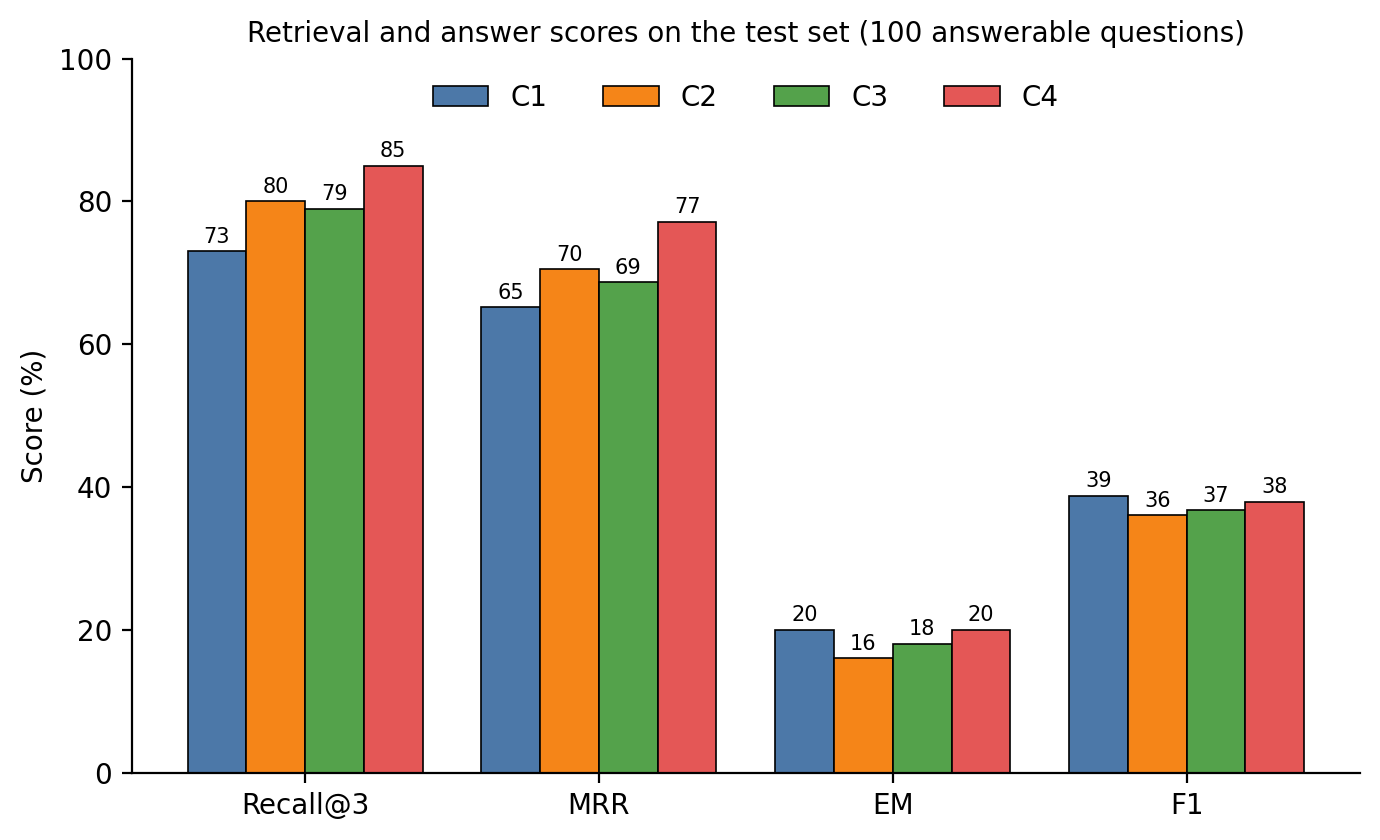

In [14]:
import matplotlib.pyplot as plt
import numpy as np

all_conds = [("C1", c1_rows), ("C2", c2_rows), ("C3", c3_rows), ("C4", c4_rows)]
labels = [c for c, _ in all_conds]
colors = ["#4C78A8", "#F58518", "#54A24B", "#E45756"]

metrics = ["Recall@3", "MRR", "EM", "F1"]
scores_by_cond = []

for _, rows in all_conds:
    ans_rows = [r for r in rows if r.get("Recall@3") is not None]
    scores_by_cond.append([
        np.mean([r["Recall@3"] for r in ans_rows]) * 100,
        np.mean([r["MRR"] for r in ans_rows]) * 100,
        np.mean([r["EM"] for r in ans_rows]) * 100,
        np.mean([r["F1"] for r in ans_rows]) * 100,
    ])

x = np.arange(len(metrics))
w = 0.2
fig, ax = plt.subplots(figsize=(7, 4.3), dpi=200)

for i in range(4):
    vals = scores_by_cond[i]
    bars = ax.bar(x + (i - 1.5) * w, vals, w, label=labels[i],
                  color=colors[i], edgecolor="black", linewidth=0.6)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 1.2, f"{v:.0f}", ha="center", fontsize=7.5)

ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylabel("Score (%)")
ax.set_ylim(0, 100)
ax.set_title("Retrieval and answer scores on the test set (100 answerable questions)", fontsize=10)
ax.legend(ncol=4, loc="upper center", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("/kaggle/working/fig1_scores.png")
plt.show()

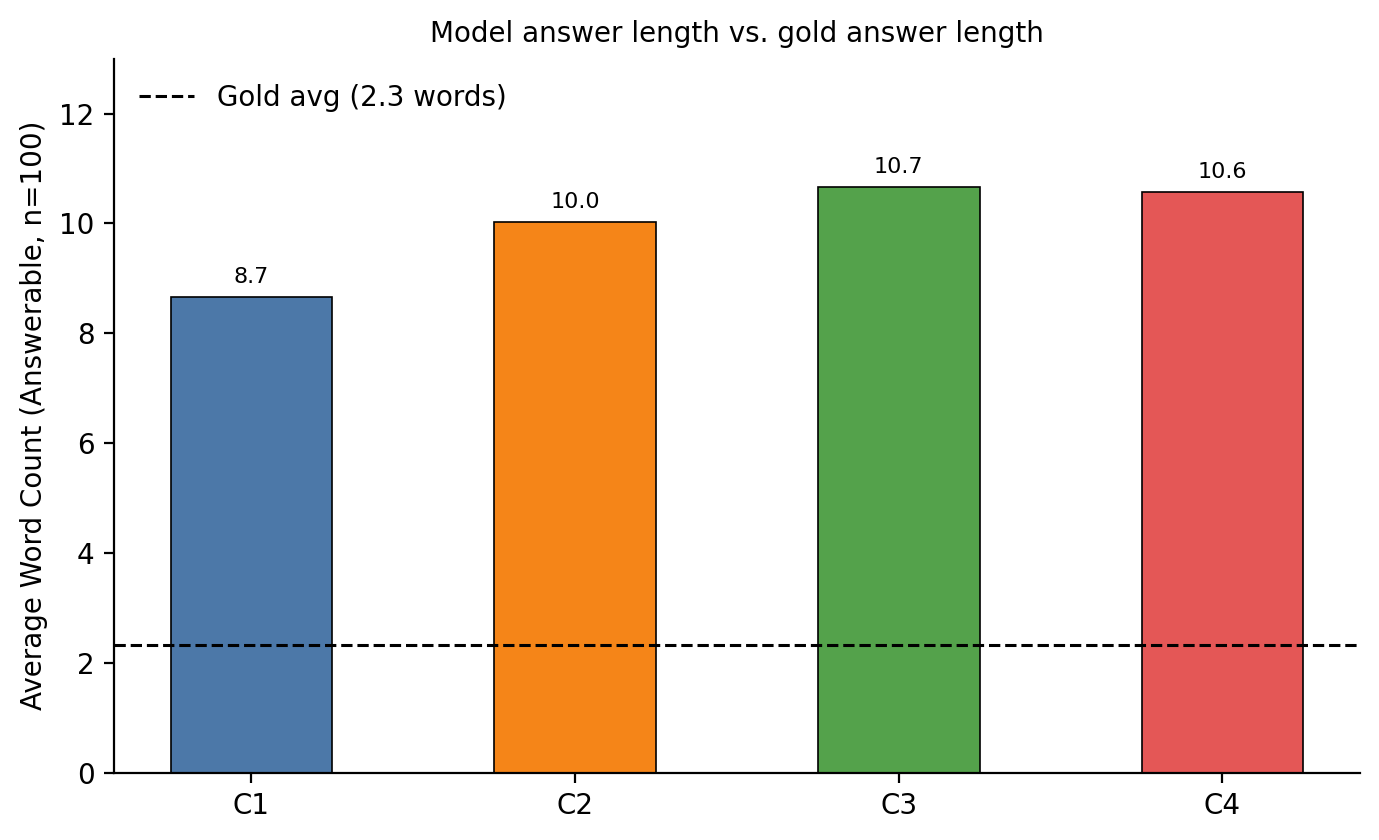

In [15]:
import matplotlib.pyplot as plt
import numpy as np

all_conds = [("C1", c1_rows), ("C2", c2_rows), ("C3", c3_rows), ("C4", c4_rows)]
labels = [c for c, _ in all_conds]
colors = ["#4C78A8", "#F58518", "#54A24B", "#E45756"]

gold_lens, ans_lens = [], []
for _, rows in all_conds:
    ans_rows = [r for r in rows if r.get("Recall@3") is not None]
    gold_lens.append(np.mean([len(words(r["gold"])) for r in ans_rows]))
    ans_lens.append(np.mean([len(words(r["output"])) for r in ans_rows]))

gold_avg = float(np.mean(gold_lens))

fig, ax = plt.subplots(figsize=(7, 4.3), dpi=200)
bars = ax.bar(labels, ans_lens, width=0.5, color=colors, edgecolor="black", linewidth=0.6)

for b, v in zip(bars, ans_lens):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.25, f"{v:.1f}", ha="center", fontsize=8)

ax.axhline(gold_avg, color="black", linestyle="--", linewidth=1.1, label=f"Gold avg ({gold_avg:.1f} words)")
ax.set_ylabel("Average Word Count (Answerable, n=100)")
ax.set_ylim(0, 13)
ax.set_title("Model answer length vs. gold answer length", fontsize=10)
ax.legend(frameon=False, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("/kaggle/working/fig2_word_counts.png")
plt.show()